# Détection des maladies de la tomate par CNN : du laboratoire au champ
**Module Deep Learning · Projet de fin de module · Cohorte 3 AI hub**

Ce notebook suit l'énoncé étape par étape :

| Étape | Contenu | Section |
|---|---|---|
| 1 | Cadrage et fiche d'impact | fiche à part (1 page) |
| 2 | Exploration, découpage sans fuite, baseline MLP | §2 |
| 3 | CNN from scratch + variantes | §3 |
| 4 | Test de robustesse PlantVillage → PlantDoc et stratégies | §4 |
| 5 | Erreurs, matrice de confusion, Grad-CAM | §5 |

**Règles de l'énoncé respectées partout** : pas de transfer learning, accuracy jamais utilisée comme critère de conclusion
(précision / rappel / F1 par classe + métrique principale justifiée), résultats toujours présentés sur données de
**laboratoire (PlantVillage)** ET **terrain (PlantDoc)**.

**Avant de lancer** : runtime GPU (Colab : *Exécution → Modifier le type d'exécution → GPU*). Pour un test rapide du pipeline,
passer `DEBUG = True` dans la cellule de configuration (quelques minutes), puis remettre `False` pour les vrais résultats.

## 0. Configuration et reproductibilité

In [2]:
import os, sys, json, copy, random, time, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.transforms import v2
from torchvision import tv_tensors
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# --- Se placer à la racine du dépôt (nécessaire sur Colab / Kaggle) ---
REPO_URL = "https://github.com/<VOTRE_COMPTE>/projet-dl-cnn-tomate.git"      # à remplacer par l'URL de VOTRE dépôt
if not Path("scripts/download_data.py").exists():
    if Path("../scripts/download_data.py").exists():                   # notebook lancé depuis notebooks/
        os.chdir("..")
    else:                                                              # Colab : notebook ouvert seul
        import subprocess
        subprocess.run(["git", "clone", REPO_URL, "projet"], check=True)
        os.chdir("projet")
print("Dossier de travail :", Path.cwd())

# ------------------------- PARAMÈTRES (modifiables) -------------------------
DEBUG       = False          # True = mini-jeu de données + 2 epochs, pour vérifier que tout tourne
SEED        = 42
IMG_SIZE    = 96             # côté des images (carré). 64 = plus rapide, 128 = plus de détails
BATCH       = 64
EPOCHS      = 25             # epochs max (arrêt anticipé selon PATIENCE)
PATIENCE    = 6
LR          = 1e-3
NUM_WORKERS = 2              # 0 si problème avec le DataLoader (ex. Windows)
DATA        = Path("data")   # dossier produit par scripts/download_data.py
OUT         = Path("outputs")
# -----------------------------------------------------------------------------
if DEBUG:
    EPOCHS, PATIENCE = 2, 2
for sub in ("figures", "models", "tables"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


set_seed()
print("Python", platform.python_version(), "| torch", torch.__version__, "| device :", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (très lent : activez un GPU)")

Dossier de travail : /content/projet_cnn_tomate
Python 3.13.16 | torch 2.14.1+cu130 | device : cuda | Tesla T4


## 1. Étape 1 : cadrage et fiche d'impact
La fiche d'impact (1 page) est un livrable séparé : utilisateur final, culture et maladies ciblées, coût d'une erreur,
changement concret pour l'agriculteur. **Les choix de ce notebook en découlent** : culture = tomate, et métrique principale
= rappel macro (une maladie non détectée coûte plus cher qu'une fausse alerte), justifiée en §2.4.

## 2. Étape 2 : données, découpage sans fuite, baseline MLP
### 2.1 Téléchargement et préparation
Le script `scripts/download_data.py` télécharge PlantVillage (Hugging Face, split groupé par feuille) et PlantDoc (GitHub),
restreint le tout à la **tomate**, aligne les classes sur un espace commun, retire les doublons et écrit des **manifestes CSV**.
Ce notebook ne lit que ces manifestes, ce qui rend le découpage auditable.

In [3]:
if not (DATA / "manifest_plantvillage.csv").exists():
    !pip -q install datasets
    !python scripts/download_data.py --data-dir {DATA} --seed {SEED}

report = json.loads((DATA / "data_report.json").read_text())
CLASSES = report["classes"]
K = len(CLASSES)
C2I = {c: i for i, c in enumerate(CLASSES)}
HEALTHY = C2I["healthy"]
print(K, "classes communes :", CLASSES)
print("\nContrôle de fuite PlantVillage (feuilles partagées entre splits) :", report.get("plantvillage_leaf_overlap"))
print("Part d'images avec regroupement par feuille réel, par classe :", report.get("plantvillage_leaf_grouped_share_by_class"))
print("(une classe à 0 = un identifiant par image : fuite possible pour cette classe, à signaler dans les limites)")
print("\nDoublons PlantDoc traités :")
for d in report["plantdoc_duplicates_removed"]:
    print(" -", d["type"], d["fichiers"])

[PlantDoc] clone partiel (dossiers Tomato uniquement)...
Cloning into 'data/raw/PlantDoc-Dataset'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 59 (delta 0), reused 47 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (59/59), 100.09 KiB | 2.86 MiB/s, done.
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), 689.24 KiB | 19.69 MiB/s, done.
remote: Enumerating objects: 743, done.
remote: Counting objects: 100% (743/743), done.
remote: Compressing objects: 100% (743/743), done.
remote: Total 743 (delta 0), reused 743 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (743/743), 225.36 MiB | 33.71 MiB/s, done.
Updating files: 100% (749/749), done.
[PlantDoc] 3 groupes de doublons traités
split   

### 2.2 Exploration : classes, déséquilibre, qualité, exemples

PlantVillage (laboratoire) : 15080 images


split,train,val,test
label,,,
healthy,1080,185,326
bacterial_spot,1463,240,424
early_blight,688,112,200
late_blight,1310,217,382
leaf_mold,656,104,192
septoria_leaf_spot,1202,209,360
yellow_leaf_curl_virus,3676,612,1069
mosaic_virus,256,42,75


PlantDoc (terrain) : 740 images


split,train,val,test
label,,,
healthy,47,8,8
bacterial_spot,86,15,8
early_blight,67,12,9
late_blight,86,15,10
leaf_mold,72,13,6
septoria_leaf_spot,118,21,10
yellow_leaf_curl_virus,59,11,5
mosaic_virus,37,7,10


PlantVillage : classe max / classe min = 5357 / 373 = x14.4
PlantDoc : classe max / classe min = 149 / 54 = x2.8


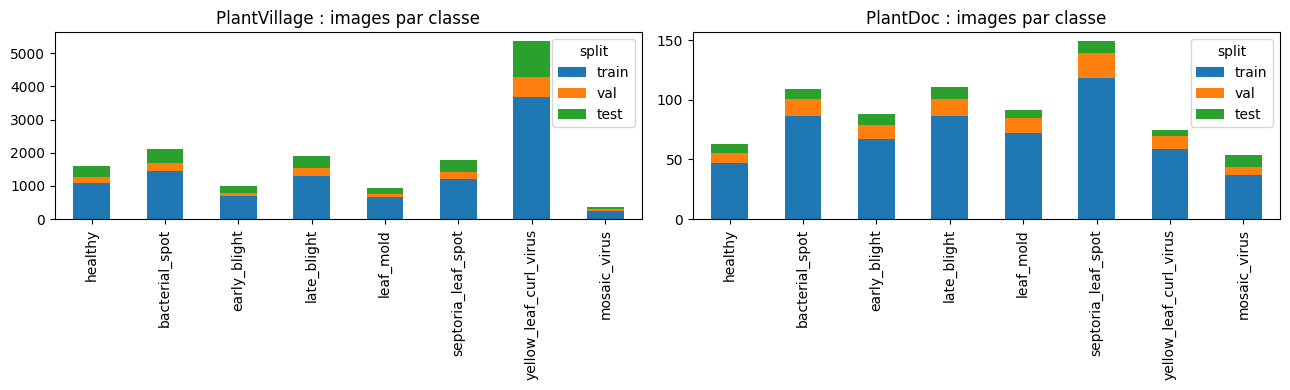

In [4]:
man_pv = pd.read_csv(DATA / "manifest_plantvillage.csv")
man_pd = pd.read_csv(DATA / "manifest_plantdoc.csv")

def counts(man):
    t = man.groupby(["label", "split"]).size().unstack(1).reindex(CLASSES).fillna(0).astype(int)
    return t[[c for c in ("train", "val", "test") if c in t.columns]]

ct_pv, ct_pd = counts(man_pv), counts(man_pd)
print("PlantVillage (laboratoire) :", len(man_pv), "images"); display(ct_pv)
print("PlantDoc (terrain) :", len(man_pd), "images"); display(ct_pd)

for name, ct in (("PlantVillage", ct_pv), ("PlantDoc", ct_pd)):
    tot = ct.sum(axis=1)
    print(f"{name} : classe max / classe min = {tot.max()} / {tot.min()} = x{tot.max()/tot.min():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ct_pv.plot.bar(stacked=True, ax=ax[0], title="PlantVillage : images par classe"); ax[0].set_xlabel("")
ct_pd.plot.bar(stacked=True, ax=ax[1], title="PlantDoc : images par classe"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(OUT / "figures" / "eda_classes.png", dpi=130); plt.show()

Tailles d'origine PlantVillage :


,largeur,hauteur
min,256.0,256.0
50%,256.0,256.0
max,256.0,256.0


Tailles d'origine PlantDoc :


,largeur,hauteur
min,115.0,69.0
50%,640.0,568.5
max,6000.0,4000.0


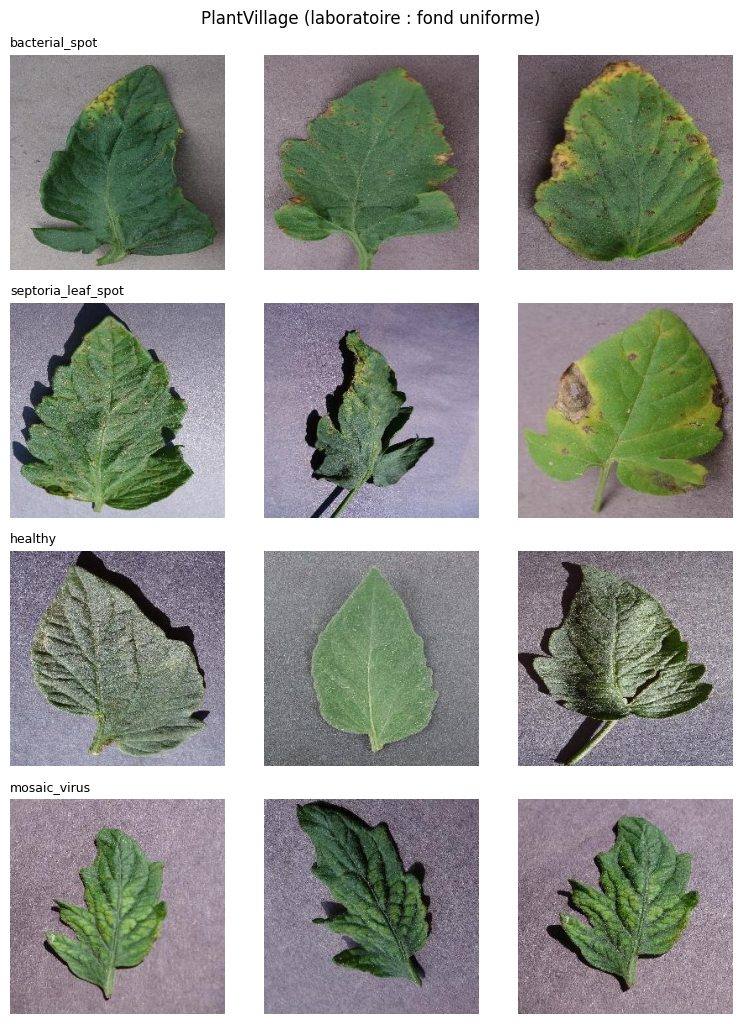

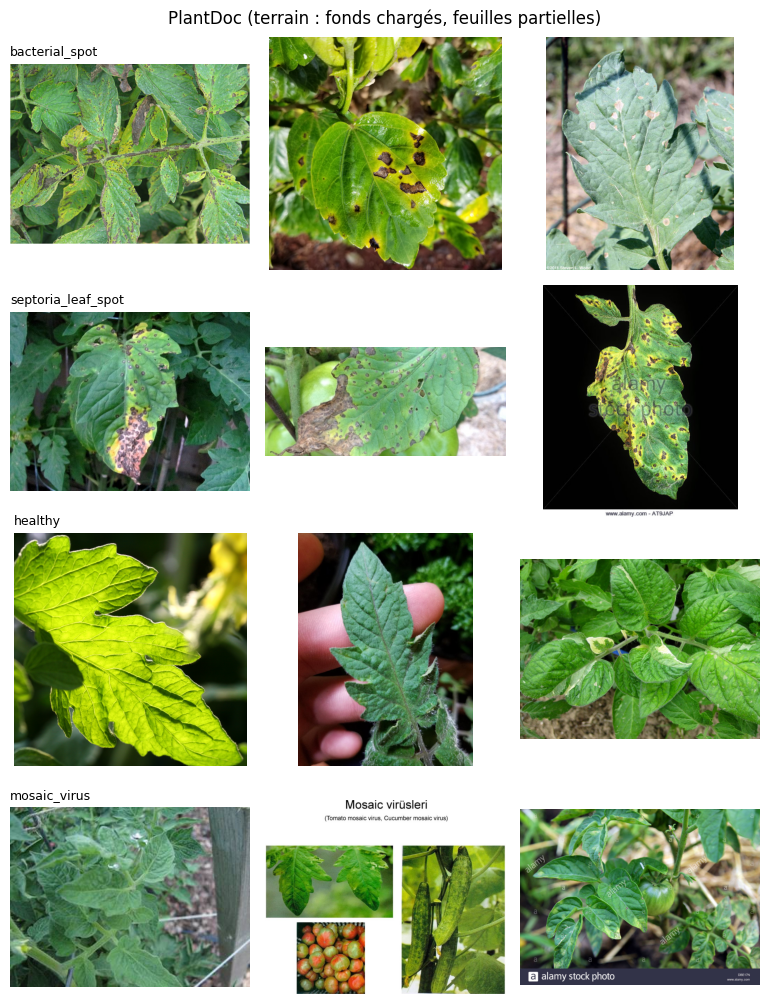

In [5]:
# Qualité : tailles d'origine (échantillon), images trop petites, exemples
def size_stats(man, n=400):
    s = man.sample(min(n, len(man)), random_state=SEED)
    wh = np.array([Image.open(DATA / p).size for p in s["path"]])
    return pd.DataFrame({"largeur": wh[:, 0], "hauteur": wh[:, 1]}).describe().loc[["min", "50%", "max"]]

print("Tailles d'origine PlantVillage :"); display(size_stats(man_pv))
print("Tailles d'origine PlantDoc :"); display(size_stats(man_pd))

def show_samples(man, title, fname, n_cls=4, per_cls=3, seed=SEED):
    rng = np.random.RandomState(seed)
    classes = [c for c in CLASSES if c in set(man.label)]
    classes = list(rng.choice(classes, min(n_cls, len(classes)), replace=False))
    fig, axes = plt.subplots(len(classes), per_cls, figsize=(2.6 * per_cls, 2.6 * len(classes)))
    for i, c in enumerate(classes):
        sub = man[man.label == c].sample(per_cls, random_state=seed)
        for j, p in enumerate(sub["path"]):
            ax = axes[i, j]; ax.imshow(ImageOps.exif_transpose(Image.open(DATA / p)).convert("RGB")); ax.axis("off")
            if j == 0: ax.set_title(c, fontsize=9, loc="left")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(OUT / "figures" / fname, dpi=110); plt.show()

show_samples(man_pv, "PlantVillage (laboratoire : fond uniforme)", "exemples_plantvillage.png")
show_samples(man_pd, "PlantDoc (terrain : fonds chargés, feuilles partielles)", "exemples_plantdoc.png")

### 2.3 Découpage train / validation / test sans fuite
* **PlantVillage** : ~7 photos par feuille physique ; un tirage aléatoire par image met des quasi-copies d'une même feuille dans train et test et
  gonfle les scores. Ici le split officiel est groupé par feuille et la validation est prélevée **par feuille** (vérifié : 0 feuille partagée, voir §2.1).
* **PlantDoc** : split officiel conservé ; doublons exacts entre train et test retirés ; validation prélevée dans le train.
  Le **test PlantDoc n'est jamais utilisé** pour choisir un modèle ni un hyperparamètre.
* **Règle de sélection** : tous les choix (architecture, epoch, fraction de PlantDoc...) se font sur les jeux de **validation**.

In [6]:
def load_images(df, size=IMG_SIZE):
    arr = np.empty((len(df), size, size, 3), dtype=np.uint8)
    for i, p in enumerate(df["path"]):
        with Image.open(DATA / p) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")      # corrige l'orientation des photos de téléphone
            arr[i] = np.asarray(im.resize((size, size), Image.Resampling.BILINEAR))
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()   # uint8, N x 3 x H x W

def get_split(man, src, split):
    df = man[man.split == split]
    if DEBUG:
        df = df.sample(min(len(df), 300), random_state=SEED)
    df = df.reset_index(drop=True)
    cache = Path("cache"); cache.mkdir(exist_ok=True)
    f = cache / f"{src}_{split}_{IMG_SIZE}{'_dbg' if DEBUG else ''}.pt"
    if f.exists():
        X = torch.load(f)
    else:
        X = load_images(df); torch.save(X, f)
    y = torch.tensor(df.label.map(C2I).values, dtype=torch.long)
    return X, y, df

D, META = {}, {}
for src, man in (("pv", man_pv), ("pd", man_pd)):
    for split in ("train", "val", "test"):
        X, y, df = get_split(man, src, split)
        D[f"{src}_{split}"] = (X, y); META[f"{src}_{split}"] = df
        print(f"{src}_{split:5s} X={tuple(X.shape)}  classes présentes : {len(y.unique())}/{K}")

pv_train X=(10331, 3, 96, 96)  classes présentes : 8/8
pv_val   X=(1721, 3, 96, 96)  classes présentes : 8/8
pv_test  X=(3028, 3, 96, 96)  classes présentes : 8/8
pd_train X=(572, 3, 96, 96)  classes présentes : 8/8
pd_val   X=(102, 3, 96, 96)  classes présentes : 8/8
pd_test  X=(66, 3, 96, 96)  classes présentes : 8/8


### 2.4 Métriques, boucle d'entraînement, utilitaires
**Métrique principale : rappel macro** (moyenne du rappel de chaque classe). Justification : une maladie non détectée (faux négatif) fait
perdre la récolte, alors qu'une fausse alerte coûte un traitement inutile ; le rappel mesure directement les maladies manquées et la moyenne
macro donne le même poids aux maladies rares. Comme un modèle qui crierait « malade » partout aurait un bon rappel sur les maladies, on garde
le **rappel de la classe saine** dans la moyenne (il pénalise les fausses alertes) et on rapporte aussi deux taux opérationnels :
* **maladie manquée** = part des feuilles malades prédites « saines » ;
* **fausse alerte** = part des feuilles saines prédites « malades ».

La F1 macro et la précision macro sont rapportées en complément. L'accuracy n'apparaît que dans les courbes d'apprentissage.

In [7]:
# ------------------------------- Métriques -------------------------------
def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=list(range(K)), zero_division=0)
    present = s > 0                                  # classes présentes dans ce jeu
    sick, healthy = y_true != HEALTHY, y_true == HEALTHY
    return dict(
        macro_recall=r[present].mean(), macro_f1=f[present].mean(), macro_precision=p[present].mean(),
        missed_disease=(y_pred[sick] == HEALTHY).mean() if sick.any() else np.nan,
        false_alarm=(y_pred[healthy] != HEALTHY).mean() if healthy.any() else np.nan,
        per_class=pd.DataFrame(dict(precision=p, recall=r, f1=f, support=s), index=CLASSES))

def fast_metric(y_true, y_pred, key):
    """Même résultat que metrics() pour rappel/F1 macro, sans DataFrame (utilisé par le bootstrap)."""
    cm = np.bincount(y_true * K + y_pred, minlength=K * K).reshape(K, K)
    tp, sup, pred = np.diag(cm), cm.sum(1), cm.sum(0); present = sup > 0
    rec = tp / np.maximum(sup, 1)
    if key == "macro_recall":
        return rec[present].mean()
    prec = tp / np.maximum(pred, 1); f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return f1[present].mean()

def bootstrap_ci(y_true, y_pred, key="macro_recall", n=1000, seed=SEED):
    """IC à 95 % par bootstrap : indispensable car le test PlantDoc est très petit."""
    rng = np.random.RandomState(seed); y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    vals = []
    for _ in range(n):
        i = rng.randint(0, len(y_true), len(y_true))
        vals.append(fast_metric(y_true[i], y_pred[i], key))
    return np.percentile(vals, [2.5, 97.5])

# --------------------------- Dataset / augmentations ---------------------------
class RandomBackground(nn.Module):
    """Remplace un fond UNIFORME (cas PlantVillage) par une texture aléatoire. Heuristique simple :
    couleur de fond = médiane de la bordure ; feuille = pixels éloignés de cette couleur.
    Inactive si la bordure n'est pas uniforme (images de terrain)."""
    def __init__(self, p=0.5, thr=45.0, max_border_std=30.0):
        super().__init__(); self.p, self.thr, self.max_std = p, thr, max_border_std
    def forward(self, img):                                   # img : uint8 3xHxW
        if torch.rand(1).item() > self.p:
            return img
        x = img.float(); b = 4
        border = torch.cat([x[:, :b, :].flatten(1), x[:, -b:, :].flatten(1),
                            x[:, :, :b].flatten(1), x[:, :, -b:].flatten(1)], dim=1)
        if border.std(dim=1).mean() > self.max_std:
            return img
        bg = border.median(dim=1).values.view(3, 1, 1)
        m = ((x - bg).abs().sum(0) > self.thr).float()[None, None]
        m = F.max_pool2d(m, 5, 1, 2); m = -F.max_pool2d(-m, 5, 1, 2)      # fermeture morphologique
        m = m[0]
        noise = torch.rand(1, 3, 6, 6) * 255
        new_bg = F.interpolate(noise, size=x.shape[1:], mode="bilinear", align_corners=False)[0]
        return (x * m + new_bg * (1 - m)).clamp(0, 255).to(torch.uint8)

def make_tf(aug):
    """aug : 'none' | 'geo_photo' (rotation, recadrage, luminosité...) | 'geo_photo_bg' (+ changement de fond)."""
    to_float = v2.ToDtype(torch.float32, scale=True)
    if aug == "none":
        return to_float
    ops = []
    if aug == "geo_photo_bg":
        ops.append(RandomBackground(p=0.6))
    ops += [v2.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), ratio=(0.8, 1.25), antialias=True),
            v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(), v2.RandomRotation(30),
            v2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.03),
            v2.RandomApply([v2.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.25),
            to_float]
    return v2.Compose(ops)

class TensorDS(Dataset):
    def __init__(self, X, y, aug="none"):
        self.X, self.y, self.tf = X, y, make_tf(aug)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.tf(tv_tensors.Image(self.X[i])).as_subclass(torch.Tensor), self.y[i]

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(X[i:i + bs].to(DEVICE).float() / 255).float().cpu())
    return torch.cat(out)                                      # logits

# ------------------------------- Modèles -------------------------------
class Normalize01(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer("m", torch.tensor([0.5, 0.5, 0.5]).view(1, 3, 1, 1))
        self.register_buffer("s", torch.tensor([0.5, 0.5, 0.5]).view(1, 3, 1, 1))
    def forward(self, x): return (x - self.m) / self.s         # entrée : float dans [0, 1]

class MLP(nn.Module):
    def __init__(self, n_classes, size=IMG_SIZE, hidden=(512, 256), dropout=0.3):
        super().__init__()
        self.norm = Normalize01(); layers, d = [nn.Flatten()], 3 * size * size
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(inplace=True), nn.Dropout(dropout)]; d = h
        layers.append(nn.Linear(d, n_classes)); self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(self.norm(x))

def conv_block(cin, cout, bn, pool):
    layers = []
    for i in range(2):                                         # 2 convolutions 3x3 par bloc
        layers.append(nn.Conv2d(cin if i == 0 else cout, cout, 3, padding=1, bias=not bn))
        if bn: layers.append(nn.BatchNorm2d(cout))
        layers.append(nn.ReLU(inplace=True))
    if pool: layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class SmallCNN(nn.Module):
    """Petit CNN : blocs (conv-[BN]-ReLU) x2 + MaxPool, global average pooling, dropout, couche linéaire."""
    def __init__(self, n_classes, widths=(32, 64, 128), bn=True, dropout=0.4):
        super().__init__()
        self.norm = Normalize01(); blocks, cin = [], 3
        for i, w in enumerate(widths):
            blocks.append(conv_block(cin, w, bn, pool=(i < len(widths) - 1))); cin = w   # pas de pool au dernier bloc
        self.features = nn.Sequential(*blocks)
        self.pool, self.drop, self.fc = nn.AdaptiveAvgPool2d(1), nn.Dropout(dropout), nn.Linear(cin, n_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        return self.fc(self.drop(self.pool(self.features(self.norm(x))).flatten(1)))

def n_params(m): return sum(p.numel() for p in m.parameters())

# ------------------------------ Entraînement ------------------------------
HISTORY, MODELS, VAL_SCORE = {}, {}, {}

def train_model(name, model, train, val, aug="none", epochs=None, lr=LR, patience=PATIENCE,
                sampler_weights=None, epoch_size=None, wd=1e-4):
    """Entraîne et garde le meilleur epoch selon le RAPPEL MACRO de validation (métrique principale)."""
    set_seed(); epochs = epochs or EPOCHS
    Xtr, ytr = train; Xva, yva = val
    model = model.to(DEVICE)
    counts = torch.bincount(ytr, minlength=K).float().clamp(min=1)
    cw = (counts.sum() / (K * counts)).sqrt().to(DEVICE)       # poids de classes atténués (racine carrée)
    crit = nn.CrossEntropyLoss(weight=cw)
    bs = min(BATCH, len(Xtr))
    ds = TensorDS(Xtr, ytr, aug)
    if sampler_weights is not None:
        sampler = WeightedRandomSampler(sampler_weights, num_samples=epoch_size or len(ds), replacement=True)
        dl = DataLoader(ds, batch_size=bs, sampler=sampler, num_workers=NUM_WORKERS, drop_last=True)
    else:
        dl = DataLoader(ds, batch_size=bs, shuffle=True, num_workers=NUM_WORKERS, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    hist, best, best_state, bad = [], -1.0, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl, tc, n = 0.0, 0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                out = model(xb); loss = crit(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(yb); tc += (out.argmax(1) == yb).sum().item(); n += len(yb)
        sched.step()
        lv = predict(model, Xva); vl = F.cross_entropy(lv, yva).item()
        yp = lv.argmax(1).numpy(); m = metrics(yva.numpy(), yp)
        hist.append(dict(epoch=ep, train_loss=tl / n, train_acc=tc / n, val_loss=vl,
                         val_acc=float((yp == yva.numpy()).mean()),
                         val_macro_recall=m["macro_recall"], val_macro_f1=m["macro_f1"]))
        if m["macro_recall"] > best:
            best, bad, best_state = m["macro_recall"], 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
        print(f"[{name}] ep {ep:02d} loss {tl/n:.3f}/{vl:.3f}  rappel macro val {m['macro_recall']:.3f}  ({time.time()-t0:.0f}s)")
        if bad >= patience:
            print(f"[{name}] arrêt anticipé (patience {patience})"); break
    model.load_state_dict(best_state)
    HISTORY[name] = pd.DataFrame(hist); MODELS[name] = model; VAL_SCORE[name] = best
    torch.save(model.state_dict(), OUT / "models" / f"{name}.pt")
    return model

def plot_history(names, fname):
    fig, ax = plt.subplots(2, len(names), figsize=(4.6 * len(names), 7), squeeze=False)
    for j, n in enumerate(names):
        h = HISTORY[n]
        ax[0, j].plot(h.epoch, h.train_loss, label="train"); ax[0, j].plot(h.epoch, h.val_loss, label="val")
        ax[0, j].set_title(f"{n}\nloss"); ax[0, j].legend()
        ax[1, j].plot(h.epoch, h.train_acc, label="train"); ax[1, j].plot(h.epoch, h.val_acc, label="val")
        ax[1, j].set_title("accuracy (courbes uniquement)"); ax[1, j].set_xlabel("epoch"); ax[1, j].legend()
    plt.tight_layout(); plt.savefig(OUT / "figures" / fname, dpi=130); plt.show()

# ------------------------ Évaluation labo + terrain ------------------------
RESULTS, PER_CLASS, PREDS = [], {}, {}
TESTS = {"labo (PlantVillage test)": "pv_test", "terrain (PlantDoc test)": "pd_test"}

def evaluate_all(name, model=None):
    model = MODELS[name] if model is None else model
    RESULTS[:] = [r for r in RESULTS if r["experience"] != name]       # ré-évaluation sans doublons
    for tname, key in TESTS.items():
        X, y = D[key]; yt = y.numpy(); yp = predict(model, X).argmax(1).numpy()
        m = metrics(yt, yp); lo, hi = bootstrap_ci(yt, yp)
        RESULTS.append(dict(experience=name, test=tname, rappel_macro=m["macro_recall"], ic95_bas=lo, ic95_haut=hi,
                            f1_macro=m["macro_f1"], precision_macro=m["macro_precision"],
                            maladie_manquee=m["missed_disease"], fausse_alerte=m["false_alarm"], n_test=len(yt)))
        PER_CLASS[(name, tname)] = m["per_class"]; PREDS[(name, key)] = yp

def show_results(names=None):
    df = pd.DataFrame(RESULTS)
    if names: df = df[df.experience.isin(names)]
    return df.round(3).set_index(["experience", "test"])

### 2.5 Baseline : MLP sur images aplaties
Rôle : justifier le CNN. Un MLP ignore la structure spatiale (chaque pixel est une entrée indépendante), n'est pas robuste aux décalages
et possède énormément de paramètres pour peu de structure exploitée.

[mlp_baseline] ep 01 loss 1.273/0.686  rappel macro val 0.729  (5s)
[mlp_baseline] ep 02 loss 0.788/0.559  rappel macro val 0.778  (8s)
[mlp_baseline] ep 03 loss 0.661/0.524  rappel macro val 0.802  (10s)
[mlp_baseline] ep 04 loss 0.588/0.484  rappel macro val 0.814  (13s)
[mlp_baseline] ep 05 loss 0.509/0.482  rappel macro val 0.811  (18s)
[mlp_baseline] ep 06 loss 0.466/0.447  rappel macro val 0.802  (22s)
[mlp_baseline] ep 07 loss 0.403/0.402  rappel macro val 0.829  (25s)
[mlp_baseline] ep 08 loss 0.358/0.390  rappel macro val 0.848  (28s)
[mlp_baseline] ep 09 loss 0.301/0.403  rappel macro val 0.842  (32s)
[mlp_baseline] ep 10 loss 0.278/0.422  rappel macro val 0.842  (35s)
[mlp_baseline] ep 11 loss 0.235/0.373  rappel macro val 0.865  (38s)
[mlp_baseline] ep 12 loss 0.219/0.395  rappel macro val 0.858  (41s)
[mlp_baseline] ep 13 loss 0.195/0.391  rappel macro val 0.872  (44s)
[mlp_baseline] ep 14 loss 0.161/0.367  rappel macro val 0.873  (48s)
[mlp_baseline] ep 15 loss 0.133/0.39

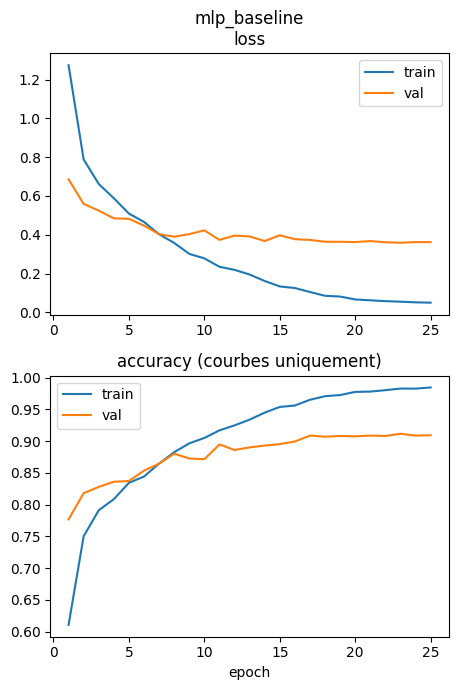

paramètres : 14,289,672


rappel_macro  ic95_bas  ic95_haut  \
experience   test                                                          
mlp_baseline labo (PlantVillage test)         0.851     0.835      0.867   
             terrain (PlantDoc test)          0.189     0.112      0.257   

                                       f1_macro  precision_macro  \
experience   test                                                  
mlp_baseline labo (PlantVillage test)     0.853            0.856   
             terrain (PlantDoc test)      0.091            0.085   

                                       maladie_manquee  fausse_alerte  n_test  
experience   test                                                              
mlp_baseline labo (PlantVillage test)            0.007          0.043    3028  
             terrain (PlantDoc test)             0.000          1.000      66

In [8]:
mlp = train_model("mlp_baseline", MLP(K), D["pv_train"], D["pv_val"])
plot_history(["mlp_baseline"], "courbes_mlp.png")
evaluate_all("mlp_baseline")
print("paramètres :", f"{n_params(mlp):,}")
show_results(["mlp_baseline"])

## 3. Étape 3 : CNN conçu from scratch + variantes
Trois variantes pour isoler l'effet de chaque choix de conception :
1. `cnn_sansBN` : 3 blocs, sans batch normalization ;
2. `cnn_BN` : mêmes 3 blocs **avec** batch normalization (effet de la BN) ;
3. `cnn_BN_profond` : 4 blocs avec BN (effet de la profondeur).

Le meilleur modèle est choisi sur la **validation PlantVillage** (jamais sur le test PlantDoc).

[cnn_sansBN] ep 01 loss 1.466/0.841  rappel macro val 0.659  (8s)
[cnn_sansBN] ep 02 loss 0.924/0.819  rappel macro val 0.639  (13s)
[cnn_sansBN] ep 03 loss 0.706/0.564  rappel macro val 0.802  (18s)
[cnn_sansBN] ep 04 loss 0.582/0.433  rappel macro val 0.835  (24s)
[cnn_sansBN] ep 05 loss 0.489/0.345  rappel macro val 0.841  (29s)
[cnn_sansBN] ep 06 loss 0.431/0.251  rappel macro val 0.907  (35s)
[cnn_sansBN] ep 07 loss 0.353/0.232  rappel macro val 0.910  (41s)
[cnn_sansBN] ep 08 loss 0.331/0.262  rappel macro val 0.899  (46s)
[cnn_sansBN] ep 09 loss 0.308/0.262  rappel macro val 0.889  (52s)
[cnn_sansBN] ep 10 loss 0.251/0.206  rappel macro val 0.922  (58s)
[cnn_sansBN] ep 11 loss 0.213/0.157  rappel macro val 0.940  (63s)
[cnn_sansBN] ep 12 loss 0.194/0.152  rappel macro val 0.944  (69s)
[cnn_sansBN] ep 13 loss 0.168/0.130  rappel macro val 0.958  (74s)
[cnn_sansBN] ep 14 loss 0.158/0.109  rappel macro val 0.953  (80s)
[cnn_sansBN] ep 15 loss 0.128/0.127  rappel macro val 0.959  (8

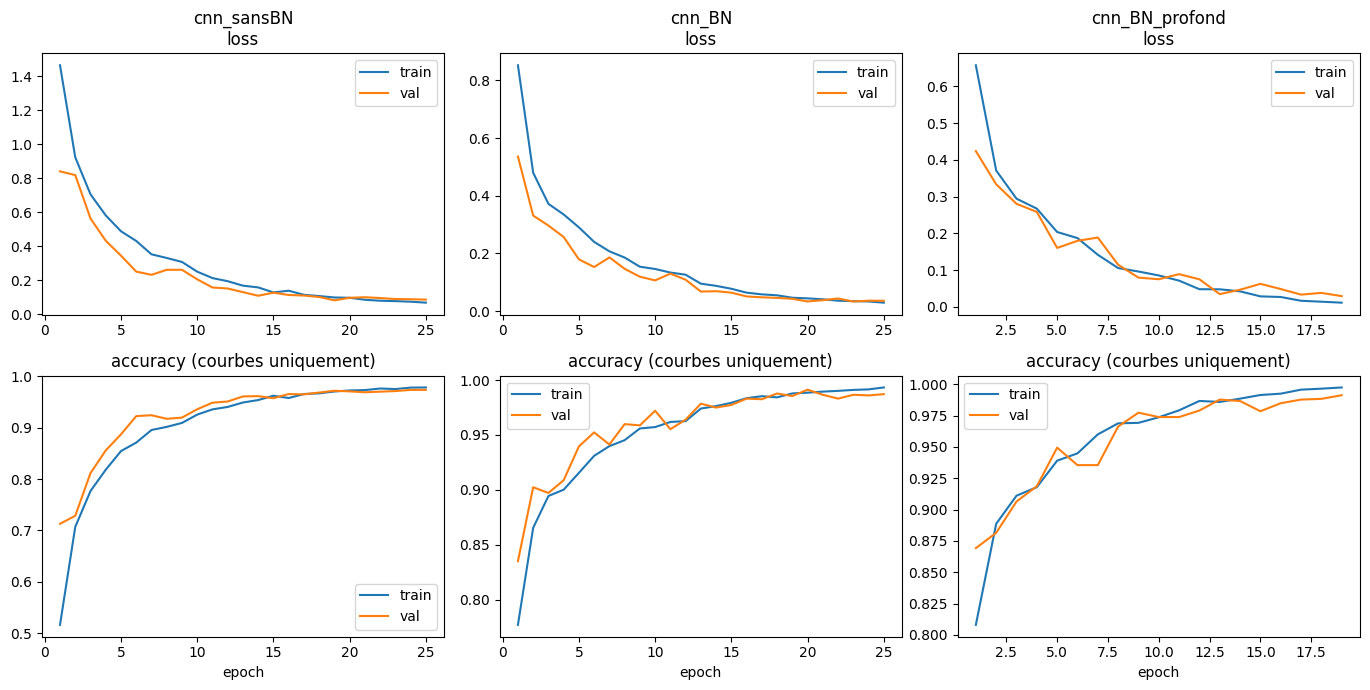

rappel_macro  ic95_bas  ic95_haut  \
experience     test                                                          
mlp_baseline   labo (PlantVillage test)         0.851     0.835      0.867   
               terrain (PlantDoc test)          0.189     0.112      0.257   
cnn_sansBN     labo (PlantVillage test)         0.967     0.960      0.975   
               terrain (PlantDoc test)          0.128     0.073      0.188   
cnn_BN         labo (PlantVillage test)         0.989     0.985      0.993   
               terrain (PlantDoc test)          0.193     0.122      0.265   
cnn_BN_profond labo (PlantVillage test)         0.983     0.978      0.989   
               terrain (PlantDoc test)          0.156     0.085      0.226   

                                         f1_macro  precision_macro  \
experience     test                                                  
mlp_baseline   labo (PlantVillage test)     0.853            0.856   
               terrain (PlantDoc test)      0.091            0.085   
cnn_sansBN     labo (PlantVillage test)     0.966            0.965   
               terrain (PlantDoc test)      0.076            0.105   
cnn_BN         labo (PlantVillage test)     0.988            0.987   
               terrain (PlantDoc test)      0.124            0.092   
cnn_BN_profond labo (PlantVillage test)     0.983            0.983   
               terrain (PlantDoc test)      0.097            0.075   

                                         maladie_manquee  fausse_alerte  \
experience     test                                                       
mlp_baseline   labo (PlantVillage test)            0.007          0.043   
               terrain (PlantDoc test)             0.000          1.000   
cnn_sansBN     labo (PlantVillage test)            0.000          0.018   
               terrain (PlantDoc test)             0.034          1.000   
cnn_BN         labo (PlantVillage test)            0.001          0.006   
               terrain (PlantDoc test)             0.000          1.000   
cnn_BN_profond labo (PlantVillage test)            0.000          0.006   
               terrain (PlantDoc test)             0.000          1.000   

                                         n_test  
experience     test                              
mlp_baseline   labo (PlantVillage test)    3028  
               terrain (PlantDoc test)       66  
cnn_sansBN     labo (PlantVillage test)    3028  
               terrain (PlantDoc test)       66  
cnn_BN         labo (PlantVillage test)    3028  
               terrain (PlantDoc test)       66  
cnn_BN_profond labo (PlantVillage test)    3028  
               terrain (PlantDoc test)       66

In [9]:
VARIANTS = {
    "cnn_sansBN":     dict(widths=(32, 64, 128),      bn=False),
    "cnn_BN":         dict(widths=(32, 64, 128),      bn=True),
    "cnn_BN_profond": dict(widths=(32, 64, 128, 256), bn=True),
}
for n, cfg in VARIANTS.items():
    m = train_model(n, SmallCNN(K, **cfg), D["pv_train"], D["pv_val"])
    evaluate_all(n); print(f"{n} : {n_params(m):,} paramètres\n")
plot_history(list(VARIANTS), "courbes_cnn_variantes.png")
show_results(["mlp_baseline", *VARIANTS])

In [10]:
# Surapprentissage : écart train / validation au meilleur epoch (à commenter dans le rapport)
rows = []
for n in ["mlp_baseline", *VARIANTS]:
    h = HISTORY[n]; b = h.loc[h.val_macro_recall.idxmax()]
    rows.append(dict(modele=n, epoch_retenu=int(b.epoch), acc_train=b.train_acc, acc_val=b.val_acc,
                     ecart_acc=b.train_acc - b.val_acc, loss_train=b.train_loss, loss_val=b.val_loss))
display(pd.DataFrame(rows).round(3))

BEST_ARCH = max(VARIANTS, key=lambda n: VAL_SCORE[n])          # choix sur la VALIDATION labo
print("Architecture retenue (rappel macro de validation PlantVillage) :", BEST_ARCH, f"({VAL_SCORE[BEST_ARCH]:.3f})")

,modele,epoch_retenu,acc_train,acc_val,ecart_acc,loss_train,loss_val
0,mlp_baseline,23,0.983,0.912,0.071,0.055,0.359
1,cnn_sansBN,24,0.978,0.974,0.004,0.074,0.088
2,cnn_BN,20,0.989,0.991,-0.003,0.044,0.034
3,cnn_BN_profond,13,0.986,0.988,-0.002,0.048,0.035


Architecture retenue (rappel macro de validation PlantVillage) : cnn_BN_profond (0.990)


**À COMPLÉTER pour le rapport (après exécution)** : (a) le MLP vs le CNN : écart de performance et de nombre de paramètres ;
(b) effet de la BN : vitesse de convergence, stabilité des courbes, résultat final ; (c) effet de la profondeur ;
(d) surapprentissage : à partir de quel epoch val_loss remonte-t-elle ? quel écart train/val ?

## 4. Étape 4 : test de robustesse (cœur du projet)
### 4.1 Entraîner sur PlantVillage, tester sur PlantDoc : mesurer la chute
Les modèles ci-dessus sont tous entraînés sur PlantVillage seul. Le tableau et le graphique comparent leur performance **labo** et **terrain**.
Rappel : le test PlantDoc ne compte que quelques dizaines d'images ; **les intervalles de confiance à 95 %** (bootstrap) sont à lire avant toute conclusion.

test,labo (PlantVillage test),terrain (PlantDoc test),chute
experience,,,
mlp_baseline,0.851,0.189,0.662
cnn_sansBN,0.967,0.128,0.840
cnn_BN,0.989,0.193,0.796
cnn_BN_profond,0.983,0.156,0.828


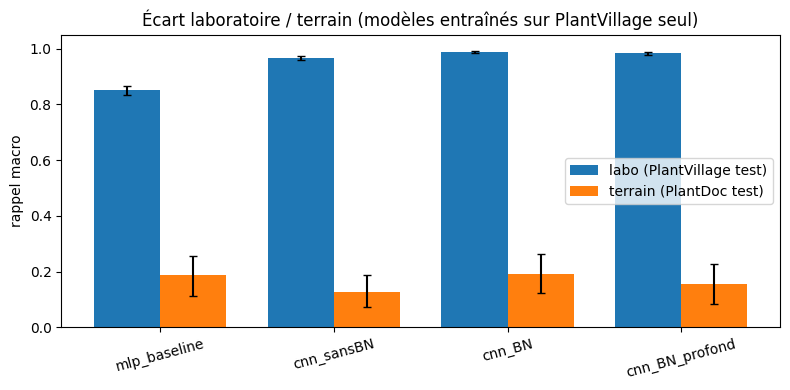

In [11]:
res = pd.DataFrame(RESULTS)
piv = res.pivot(index="experience", columns="test", values="rappel_macro")
piv["chute"] = piv["labo (PlantVillage test)"] - piv["terrain (PlantDoc test)"]
display(piv.loc[["mlp_baseline", *VARIANTS]].round(3))
show_results(["mlp_baseline", *VARIANTS])

fig, ax = plt.subplots(figsize=(8, 4)); names = ["mlp_baseline", *VARIANTS]
x = np.arange(len(names)); w = 0.38
for k, (t, c) in enumerate(zip(TESTS, ("tab:blue", "tab:orange"))):
    v = res[res.test == t].set_index("experience").loc[names]
    err = np.vstack([v.rappel_macro - v.ic95_bas, v.ic95_haut - v.rappel_macro]).clip(min=0)
    ax.bar(x + (k - 0.5) * w, v.rappel_macro, w, yerr=err, capsize=3, label=t, color=c)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15); ax.set_ylabel("rappel macro"); ax.set_ylim(0, 1.05)
ax.set_title("Écart laboratoire / terrain (modèles entraînés sur PlantVillage seul)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "chute_labo_terrain.png", dpi=130); plt.show()

### 4.2 Stratégies pour réduire l'écart
**(a) Data augmentation** (entraînement PlantVillage seul) : on compare deux niveaux pour isoler l'effet du changement de fond.
* `geo_photo` : rotations, recadrages aléatoires, retournements, variations de luminosité/contraste/saturation, flou léger ;
* `geo_photo_bg` : idem + **remplacement du fond** uniforme par une texture aléatoire (heuristique de segmentation par la couleur de bordure, voir `RandomBackground`).

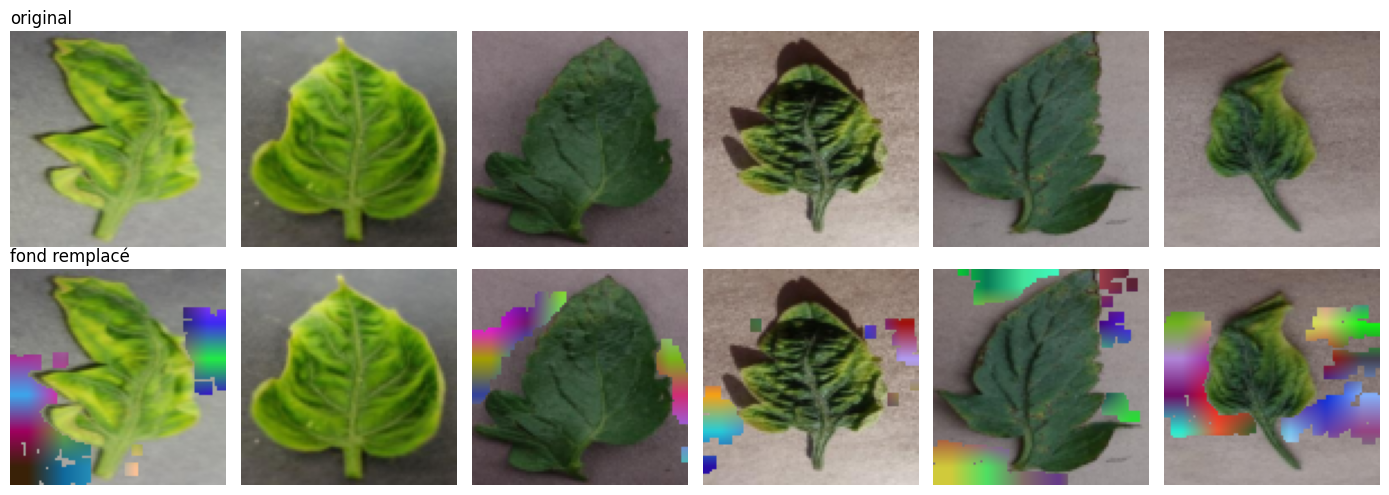

In [12]:
# Aperçu du changement de fond sur des images PlantVillage (ajuster thr dans RandomBackground si le masque est mauvais)
rb = RandomBackground(p=1.0)
idx = np.random.RandomState(SEED).choice(len(D["pv_train"][0]), 6, replace=False)
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for j, i in enumerate(idx):
    img = D["pv_train"][0][i]
    ax[0, j].imshow(img.permute(1, 2, 0)); ax[0, j].axis("off")
    ax[1, j].imshow(rb(img).permute(1, 2, 0)); ax[1, j].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("fond remplacé", loc="left")
plt.tight_layout(); plt.savefig(OUT / "figures" / "apercu_fond.png", dpi=120); plt.show()

[cnn_BN_profond+aug[geo_photo]] ep 01 loss 1.179/0.771  rappel macro val 0.641  (39s)
[cnn_BN_profond+aug[geo_photo]] ep 02 loss 0.783/0.551  rappel macro val 0.806  (80s)
[cnn_BN_profond+aug[geo_photo]] ep 03 loss 0.604/0.413  rappel macro val 0.810  (119s)
[cnn_BN_profond+aug[geo_photo]] ep 04 loss 0.484/0.474  rappel macro val 0.813  (160s)
[cnn_BN_profond+aug[geo_photo]] ep 05 loss 0.435/0.315  rappel macro val 0.871  (199s)
[cnn_BN_profond+aug[geo_photo]] ep 06 loss 0.338/0.200  rappel macro val 0.943  (240s)
[cnn_BN_profond+aug[geo_photo]] ep 07 loss 0.292/0.227  rappel macro val 0.919  (279s)
[cnn_BN_profond+aug[geo_photo]] ep 08 loss 0.271/0.140  rappel macro val 0.937  (320s)
[cnn_BN_profond+aug[geo_photo]] ep 09 loss 0.238/0.149  rappel macro val 0.936  (359s)
[cnn_BN_profond+aug[geo_photo]] ep 10 loss 0.227/0.175  rappel macro val 0.941  (400s)
[cnn_BN_profond+aug[geo_photo]] ep 11 loss 0.203/0.120  rappel macro val 0.960  (439s)
[cnn_BN_profond+aug[geo_photo]] ep 12 loss 0.

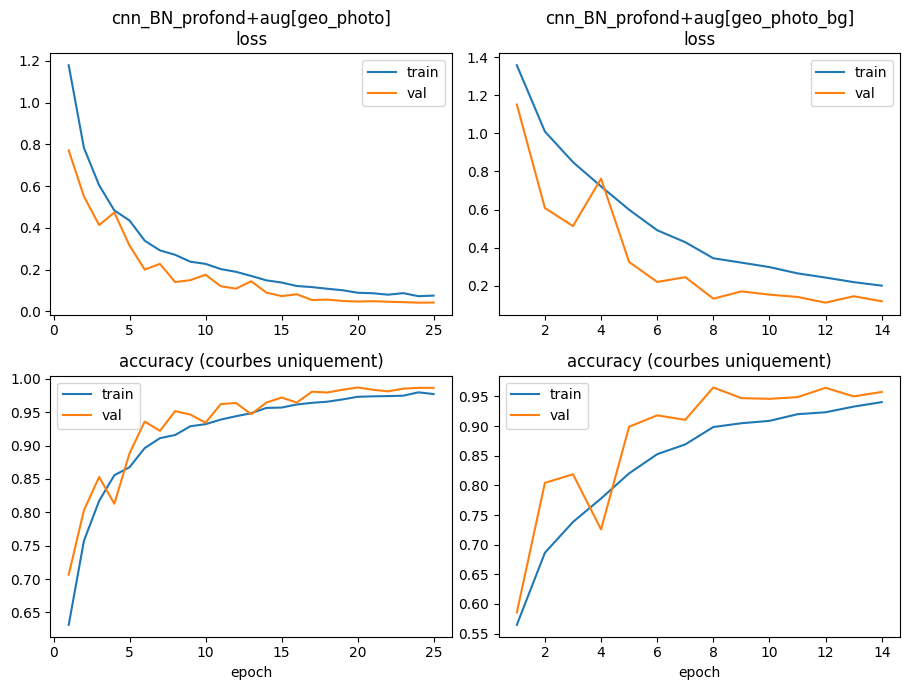

rappel_macro  \
experience                       test                                     
cnn_BN_profond                   labo (PlantVillage test)         0.983   
                                 terrain (PlantDoc test)          0.156   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)         0.984   
                                 terrain (PlantDoc test)          0.190   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)         0.946   
                                 terrain (PlantDoc test)          0.243   

                                                           ic95_bas  \
experience                       test                                 
cnn_BN_profond                   labo (PlantVillage test)     0.978   
                                 terrain (PlantDoc test)      0.085   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)     0.980   
                                 terrain (PlantDoc test)      0.116   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)     0.937   
                                 terrain (PlantDoc test)      0.140   

                                                           ic95_haut  \
experience                       test                                  
cnn_BN_profond                   labo (PlantVillage test)      0.989   
                                 terrain (PlantDoc test)       0.226   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)      0.989   
                                 terrain (PlantDoc test)       0.272   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)      0.955   
                                 terrain (PlantDoc test)       0.359   

                                                           f1_macro  \
experience                       test                                 
cnn_BN_profond                   labo (PlantVillage test)     0.983   
                                 terrain (PlantDoc test)      0.097   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)     0.978   
                                 terrain (PlantDoc test)      0.156   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)     0.942   
                                 terrain (PlantDoc test)      0.211   

                                                           precision_macro  \
experience                       test                                        
cnn_BN_profond                   labo (PlantVillage test)            0.983   
                                 terrain (PlantDoc test)             0.075   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)            0.973   
                                 terrain (PlantDoc test)             0.250   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)            0.939   
                                 terrain (PlantDoc test)             0.246   

                                                           maladie_manquee  \
experience                       test                                        
cnn_BN_profond                   labo (PlantVillage test)            0.000   
                                 terrain (PlantDoc test)             0.000   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)            0.001   
                                 terrain (PlantDoc test)             0.000   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)            0.009   
                                 terrain (PlantDoc test)             0.086   

                                                           fausse_alerte  \
experience                       test                                      
cnn_BN_profond                   labo (PlantVillage test)          0.006   
                                 terrain (PlantDoc test)           1.000   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)          0.000   
                                 terrain (PlantDoc test)           0.875   
cnn_BN_profond+aug[geo_photo_bg] labo

In [13]:
cfg = VARIANTS[BEST_ARCH]
for aug in ("geo_photo", "geo_photo_bg"):
    n = f"{BEST_ARCH}+aug[{aug}]"
    train_model(n, SmallCNN(K, **cfg), D["pv_train"], D["pv_val"], aug=aug)
    evaluate_all(n)
plot_history([f"{BEST_ARCH}+aug[geo_photo]", f"{BEST_ARCH}+aug[geo_photo_bg]"], "courbes_augmentation.png")
show_results([BEST_ARCH, f"{BEST_ARCH}+aug[geo_photo]", f"{BEST_ARCH}+aug[geo_photo_bg]"])

**(b) Ré-entraînement (fine-tuning) de notre CNN sur une partie de PlantDoc.**
On repart du meilleur modèle augmenté et on l'adapte avec 10 %, 25 %, 50 % puis 100 % du train PlantDoc (sous-échantillonnage stratifié).
Le choix de l'epoch se fait sur la **validation PlantDoc**, jamais sur le test. On surveille aussi le labo : l'adaptation au terrain peut dégrader
la performance sur PlantVillage (oubli).

In [14]:
def subsample_stratified(y, frac, seed=SEED):
    rng, y = np.random.RandomState(seed), y.numpy(); idx = []
    for c in range(K):
        ci = np.where(y == c)[0]
        if len(ci): idx += rng.choice(ci, max(1, int(round(len(ci) * frac))), replace=False).tolist()
    return np.array(sorted(idx))

BASE = max([f"{BEST_ARCH}+aug[geo_photo]", f"{BEST_ARCH}+aug[geo_photo_bg]"], key=lambda n: VAL_SCORE[n])
print("Modèle de départ du fine-tuning :", BASE)
FT_FRACS = [0.10, 0.25, 0.50, 1.00]
Xp, yp_ = D["pd_train"]
for fr in FT_FRACS:
    n = f"finetune_PD{int(fr*100)}%"
    idx = subsample_stratified(yp_, fr)
    model = copy.deepcopy(MODELS[BASE])
    train_model(n, model, (Xp[idx], yp_[idx]), D["pd_val"], aug="geo_photo", epochs=15 if not DEBUG else 2, lr=3e-4, patience=5)
    evaluate_all(n); print(f"   {len(idx)} images PlantDoc utilisées\n")
show_results([BASE] + [f"finetune_PD{int(f*100)}%" for f in FT_FRACS])

Modèle de départ du fine-tuning : cnn_BN_profond+aug[geo_photo]
[finetune_PD10%] ep 01 loss 4.927/5.653  rappel macro val 0.268  (1s)


/tmp/ipykernel_1773/1807443561.py:159: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


[finetune_PD10%] ep 02 loss 4.997/5.481  rappel macro val 0.268  (1s)
[finetune_PD10%] ep 03 loss 5.006/5.075  rappel macro val 0.287  (2s)
[finetune_PD10%] ep 04 loss 4.802/4.812  rappel macro val 0.270  (3s)
[finetune_PD10%] ep 05 loss 4.015/4.574  rappel macro val 0.282  (3s)
[finetune_PD10%] ep 06 loss 3.266/4.490  rappel macro val 0.280  (4s)
[finetune_PD10%] ep 07 loss 3.135/4.520  rappel macro val 0.254  (4s)
[finetune_PD10%] ep 08 loss 2.671/4.531  rappel macro val 0.244  (5s)
[finetune_PD10%] arrêt anticipé (patience 5)
   59 images PlantDoc utilisées

[finetune_PD25%] ep 01 loss 5.435/5.443  rappel macro val 0.268  (1s)


/tmp/ipykernel_1773/1807443561.py:159: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


[finetune_PD25%] ep 02 loss 5.151/4.853  rappel macro val 0.286  (1s)
[finetune_PD25%] ep 03 loss 4.458/4.555  rappel macro val 0.271  (2s)
[finetune_PD25%] ep 04 loss 4.142/4.608  rappel macro val 0.237  (3s)
[finetune_PD25%] ep 05 loss 3.841/4.573  rappel macro val 0.217  (3s)
[finetune_PD25%] ep 06 loss 3.407/4.482  rappel macro val 0.213  (4s)
[finetune_PD25%] ep 07 loss 3.377/4.414  rappel macro val 0.246  (4s)
[finetune_PD25%] arrêt anticipé (patience 5)
   145 images PlantDoc utilisées

[finetune_PD50%] ep 01 loss 5.271/4.666  rappel macro val 0.260  (1s)
[finetune_PD50%] ep 02 loss 4.394/4.391  rappel macro val 0.280  (2s)
[finetune_PD50%] ep 03 loss 3.387/4.797  rappel macro val 0.259  (4s)
[finetune_PD50%] ep 04 loss 3.017/4.893  rappel macro val 0.278  (6s)
[finetune_PD50%] ep 05 loss 2.723/4.690  rappel macro val 0.306  (7s)
[finetune_PD50%] ep 06 loss 2.739/4.434  rappel macro val 0.283  (8s)
[finetune_PD50%] ep 07 loss 2.506/4.255  rappel macro val 0.265  (9s)
[finetune_P

rappel_macro  \
experience                    test                                     
cnn_BN_profond+aug[geo_photo] labo (PlantVillage test)         0.984   
                              terrain (PlantDoc test)          0.190   
finetune_PD10%                labo (PlantVillage test)         0.966   
                              terrain (PlantDoc test)          0.235   
finetune_PD25%                labo (PlantVillage test)         0.928   
                              terrain (PlantDoc test)          0.248   
finetune_PD50%                labo (PlantVillage test)         0.663   
                              terrain (PlantDoc test)          0.222   
finetune_PD100%               labo (PlantVillage test)         0.603   
                              terrain (PlantDoc test)          0.251   

                                                        ic95_bas  ic95_haut  \
experience                    test                                            
cnn_BN_profond+aug[geo_photo] labo (PlantVillage test)     0.980      0.989   
                              terrain (PlantDoc test)      0.116      0.272   
finetune_PD10%                labo (PlantVillage test)     0.959      0.973   
                              terrain (PlantDoc test)      0.143      0.348   
finetune_PD25%                labo (PlantVillage test)     0.917      0.938   
                              terrain (PlantDoc test)      0.149      0.367   
finetune_PD50%                labo (PlantVillage test)     0.643      0.681   
                              terrain (PlantDoc test)      0.125      0.338   
finetune_PD100%               labo (PlantVillage test)     0.581      0.623   
                              terrain (PlantDoc test)      0.139      0.370   

                                                        f1_macro  \
experience                    test                                 
cnn_BN_profond+aug[geo_photo] labo (PlantVillage test)     0.978   
                              terrain (PlantDoc test)      0.156   
finetune_PD10%                labo (PlantVillage test)     0.951   
                              terrain (PlantDoc test)      0.211   
finetune_PD25%                labo (PlantVillage test)     0.892   
                              terrain (PlantDoc test)      0.220   
finetune_PD50%                labo (PlantVillage test)     0.659   
                              terrain (PlantDoc test)      0.219   
finetune_PD100%               labo (PlantVillage test)     0.585   
                              terrain (PlantDoc test)      0.252   

                                                        precision_macro  \
experience                    test                                        
cnn_BN_profond+aug[geo_photo] labo (PlantVillage test)            0.973   
                              terrain (PlantDoc test)             0.250   
finetune_PD10%                labo (PlantVillage test)            0.941   
                              terrain (PlantDoc test)             0.309   
finetune_PD25%                labo (PlantVillage test)            0.882   
                              terrain (PlantDoc test)             0.307   
finetune_PD50%                labo (PlantVillage test)            0.719   
                              terrain (PlantDoc test)             0.256   
finetune_PD100%               labo (PlantVillage test)            0.635   
                              terrain (PlantDoc test)             0.300   

                                                        maladie_manquee  \
experience                    test                                        
cnn_BN_profond+aug[geo_photo] labo (PlantVillage test)            0.001   
                              terrain (PlantDoc test)             0.000   
finetune_PD10%                labo (PlantVillage test)            0.002   
                              terrain (PlantDoc test)             0.000   
finetune_PD25%                labo (PlantVillage test)            0.002   

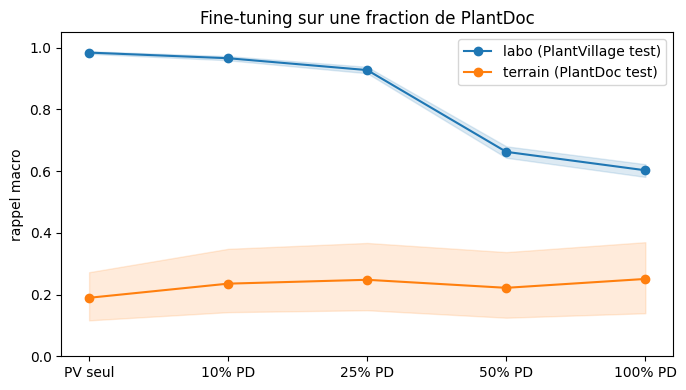

In [15]:
res = pd.DataFrame(RESULTS); names = [BASE] + [f"finetune_PD{int(f*100)}%" for f in FT_FRACS]
fig, ax = plt.subplots(figsize=(7, 4))
for t, c in zip(TESTS, ("tab:blue", "tab:orange")):
    v = res[res.test == t].set_index("experience").loc[names]
    ax.plot(range(len(names)), v.rappel_macro, "o-", color=c, label=t)
    ax.fill_between(range(len(names)), v.ic95_bas, v.ic95_haut, color=c, alpha=0.15)
ax.set_xticks(range(len(names))); ax.set_xticklabels(["PV seul"] + [f"{int(f*100)}% PD" for f in FT_FRACS])
ax.set_ylabel("rappel macro"); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("Fine-tuning sur une fraction de PlantDoc")
plt.tight_layout(); plt.savefig(OUT / "figures" / "finetune_fraction.png", dpi=130); plt.show()

**(c) Entraînement mixte PlantVillage + PlantDoc.**
Un seul entraînement sur les deux jeux. PlantDoc est très minoritaire (centaines d'images contre des milliers) : on le **sur-échantillonne**
pour qu'il représente `PD_SHARE` de chaque lot. La validation (choix de l'epoch) mélange à parts égales PlantDoc-val et un sous-ensemble de PlantVillage-val.

[cnn_BN_profond_mixte_PV+PD(aug)] ep 01 loss 1.782/1.866  rappel macro val 0.310  (45s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 02 loss 1.550/1.465  rappel macro val 0.437  (90s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 03 loss 1.385/1.436  rappel macro val 0.441  (136s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 04 loss 1.231/1.411  rappel macro val 0.462  (182s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 05 loss 1.094/1.346  rappel macro val 0.494  (227s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 06 loss 0.961/1.245  rappel macro val 0.530  (271s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 07 loss 0.879/1.227  rappel macro val 0.580  (317s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 08 loss 0.814/1.106  rappel macro val 0.581  (362s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 09 loss 0.747/1.164  rappel macro val 0.588  (409s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 10 loss 0.733/1.106  rappel macro val 0.578  (455s)
[cnn_BN_profond_mixte_PV+PD(aug)] ep 11 loss 0.691/0.989  rappel macro val 0.566  (501s)
[cnn_BN_profond_mixte_P

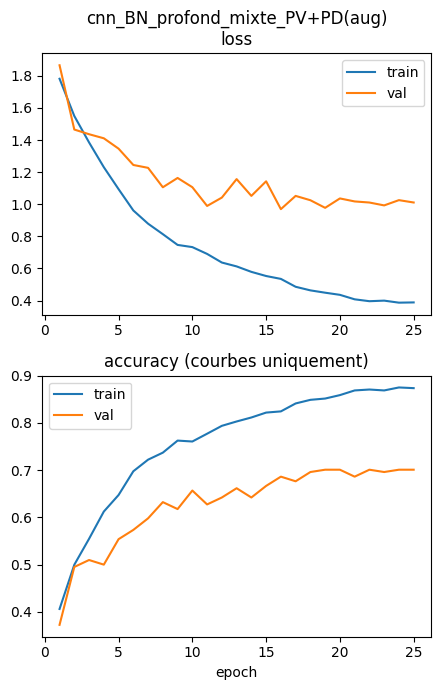

rappel_macro  \
experience                      test                                     
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)         0.973   
                                terrain (PlantDoc test)          0.451   

                                                          ic95_bas  ic95_haut  \
experience                      test                                            
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)     0.966      0.979   
                                terrain (PlantDoc test)      0.326      0.579   

                                                          f1_macro  \
experience                      test                                 
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)     0.969   
                                terrain (PlantDoc test)      0.468   

                                                          precision_macro  \
experience                      test                                        
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)            0.966   
                                terrain (PlantDoc test)             0.523   

                                                          maladie_manquee  \
experience                      test                                        
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)            0.002   
                                terrain (PlantDoc test)             0.052   

                                                          fausse_alerte  \
experience                      test                                      
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)            0.0   
                                terrain (PlantDoc test)             0.5   

                                                          n_test  
experience                      test                              
cnn_BN_profond_mixte_PV+PD(aug) labo (PlantVillage test)    3028  
                                terrain (PlantDoc test)       66

In [16]:
PD_SHARE = 0.30
Xpv, ypv = D["pv_train"]; Xpd, ypd = D["pd_train"]
Xmix, ymix = torch.cat([Xpv, Xpd]), torch.cat([ypv, ypd])
w = torch.cat([torch.full((len(ypv),), (1 - PD_SHARE) / len(ypv)), torch.full((len(ypd),), PD_SHARE / len(ypd))])

Xvp, yvp = D["pd_val"]; g = torch.Generator().manual_seed(SEED)
sel = torch.randperm(len(D["pv_val"][1]), generator=g)[: len(yvp)]
val_mix = (torch.cat([Xvp, D["pv_val"][0][sel]]), torch.cat([yvp, D["pv_val"][1][sel]]))

n_mix = f"{BEST_ARCH}_mixte_PV+PD(aug)"
train_model(n_mix, SmallCNN(K, **cfg), (Xmix, ymix), val_mix, aug="geo_photo_bg",
            sampler_weights=w, epoch_size=len(ypv))
evaluate_all(n_mix)
plot_history([n_mix], "courbes_mixte.png")
show_results([n_mix])

### 4.3 Synthèse de la robustesse
Tableau final : toutes les stratégies, sur laboratoire **et** terrain. Le modèle final est choisi sur la **validation PlantDoc** (et non sur le test).
Attention : pour les modèles dont l'epoch a déjà été choisi sur cette même validation (fine-tuning, mixte), ce score est légèrement optimiste ; l'estimation honnête reste celle du test.

In [17]:
def val_pd_score(model):
    X, y = D["pd_val"]; return metrics(y.numpy(), predict(model, X).argmax(1).numpy())["macro_recall"]

CANDIDATES = [n for n in MODELS if n != "mlp_baseline"]
val_scores = pd.Series({n: val_pd_score(MODELS[n]) for n in CANDIDATES}).sort_values(ascending=False)
print("Rappel macro sur la validation PlantDoc :"); display(val_scores.round(3))
FINAL = val_scores.index[0]
print("Modèle final retenu :", FINAL)

summary = show_results()
summary.to_csv(OUT / "tables" / "resultats_synthese.csv")
display(summary)

Rappel macro sur la validation PlantDoc :


,0
cnn_BN_profond_mixte_PV+PD(aug),0.421
finetune_PD100%,0.318
finetune_PD50%,0.306
finetune_PD10%,0.287
finetune_PD25%,0.286
cnn_BN_profond+aug[geo_photo],0.257
cnn_BN_profond+aug[geo_photo_bg],0.205
cnn_BN,0.185
cnn_BN_profond,0.184
cnn_sansBN,0.139


Modèle final retenu : cnn_BN_profond_mixte_PV+PD(aug)


rappel_macro  \
experience                       test                                     
mlp_baseline                     labo (PlantVillage test)         0.851   
                                 terrain (PlantDoc test)          0.189   
cnn_sansBN                       labo (PlantVillage test)         0.967   
                                 terrain (PlantDoc test)          0.128   
cnn_BN                           labo (PlantVillage test)         0.989   
                                 terrain (PlantDoc test)          0.193   
cnn_BN_profond                   labo (PlantVillage test)         0.983   
                                 terrain (PlantDoc test)          0.156   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)         0.984   
                                 terrain (PlantDoc test)          0.190   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)         0.946   
                                 terrain (PlantDoc test)          0.243   
finetune_PD10%                   labo (PlantVillage test)         0.966   
                                 terrain (PlantDoc test)          0.235   
finetune_PD25%                   labo (PlantVillage test)         0.928   
                                 terrain (PlantDoc test)          0.248   
finetune_PD50%                   labo (PlantVillage test)         0.663   
                                 terrain (PlantDoc test)          0.222   
finetune_PD100%                  labo (PlantVillage test)         0.603   
                                 terrain (PlantDoc test)          0.251   
cnn_BN_profond_mixte_PV+PD(aug)  labo (PlantVillage test)         0.973   
                                 terrain (PlantDoc test)          0.451   

                                                           ic95_bas  \
experience                       test                                 
mlp_baseline                     labo (PlantVillage test)     0.835   
                                 terrain (PlantDoc test)      0.112   
cnn_sansBN                       labo (PlantVillage test)     0.960   
                                 terrain (PlantDoc test)      0.073   
cnn_BN                           labo (PlantVillage test)     0.985   
                                 terrain (PlantDoc test)      0.122   
cnn_BN_profond                   labo (PlantVillage test)     0.978   
                                 terrain (PlantDoc test)      0.085   
cnn_BN_profond+aug[geo_photo]    labo (PlantVillage test)     0.980   
                                 terrain (PlantDoc test)      0.116   
cnn_BN_profond+aug[geo_photo_bg] labo (PlantVillage test)     0.937   
                                 terrain (PlantDoc test)      0.140   
finetune_PD10%                   labo (PlantVillage test)     0.959   
                                 terrain (PlantDoc test)      0.143   
finetune_PD25%                   labo (PlantVillage test)     0.917   
                                 terrain (PlantDoc test)      0.149   
finetune_PD50%                   labo (PlantVillage test)     0.643   
                                 terrain (PlantDoc test)      0.125   
finetune_PD100%                  labo (PlantVillage test)     0.581   
                                 terrain (PlantDoc test)      0.139   
cnn_BN_profond_mixte_PV+PD(aug)  labo (PlantVillage test)     0.966   
                                 terrain (PlantDoc test)      0.326   

                                                           ic95_haut  \
experience                       test                                  
mlp_baseline                     labo (PlantVillage test)      0.867   
                                 terrain (PlantDoc test)       0.257   
cnn_sansBN                       labo (PlantVillage test)      0.975   
                                 terrain (PlantDoc test)       0.188   
cnn_BN                           labo (PlantVillage test)      0.993   
                                 terrain (PlantDo

## 5. Étape 5 : analyse des erreurs et explicabilité
### 5.1 Matrices de confusion et rappel par classe
On compare le modèle **entraîné sur PlantVillage seul** (`BASE_PV`) et le **modèle final**, sur les deux jeux de test.

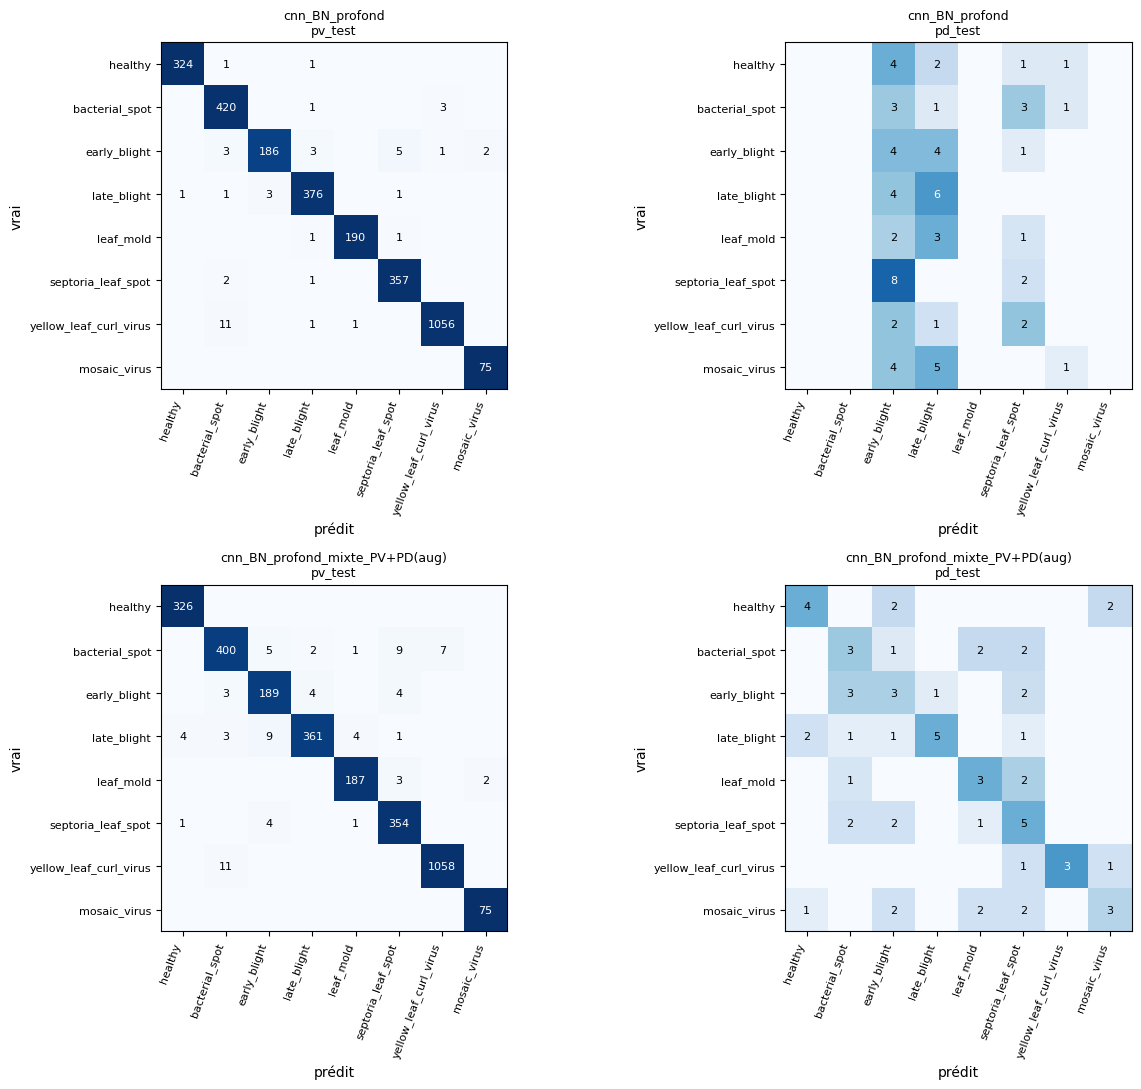

In [18]:
BASE_PV = BEST_ARCH
def plot_cm(name, key, ax):
    y = D[key][1].numpy(); yp = PREDS[(name, key)]
    cm = confusion_matrix(y, yp, labels=range(K)); rec = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(rec, vmin=0, vmax=1, cmap="Blues")
    for i in range(K):
        for j in range(K):
            if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if rec[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(CLASSES, rotation=70, ha="right", fontsize=8)
    ax.set_yticklabels(CLASSES, fontsize=8); ax.set_xlabel("prédit"); ax.set_ylabel("vrai"); ax.set_title(f"{name}\n{key}", fontsize=9)

fig, ax = plt.subplots(2, 2, figsize=(13, 11))
for i, n in enumerate([BASE_PV, FINAL]):
    for j, key in enumerate(("pv_test", "pd_test")):
        plot_cm(n, key, ax[i, j])
plt.tight_layout(); plt.savefig(OUT / "figures" / "matrices_confusion.png", dpi=130); plt.show()

In [19]:
# Précision / rappel / F1 PAR CLASSE (exigé), laboratoire ET terrain
for n in [BASE_PV, FINAL]:
    for t in TESTS:
        pc = PER_CLASS[(n, t)].round(3)
        print(f"\n=== {n} | {t} ===")
        display(pc)
        pc.to_csv(OUT / "tables" / f"par_classe_{n.replace('+','_').replace('[','').replace(']','').replace('%','pct')}_{t.split()[0]}.csv")


=== cnn_BN_profond | labo (PlantVillage test) ===


,precision,recall,f1,support
healthy,0.997,0.994,0.995,326
bacterial_spot,0.959,0.991,0.974,424
early_blight,0.984,0.930,0.956,200
late_blight,0.979,0.984,0.982,382
leaf_mold,0.995,0.990,0.992,192
septoria_leaf_spot,0.981,0.992,0.986,360
yellow_leaf_curl_virus,0.996,0.988,0.992,1069
mosaic_virus,0.974,1.000,0.987,75



=== cnn_BN_profond | terrain (PlantDoc test) ===


,precision,recall,f1,support
healthy,0.000,0.000,0.000,8
bacterial_spot,0.000,0.000,0.000,8
early_blight,0.129,0.444,0.200,9
late_blight,0.273,0.600,0.375,10
leaf_mold,0.000,0.000,0.000,6
septoria_leaf_spot,0.200,0.200,0.200,10
yellow_leaf_curl_virus,0.000,0.000,0.000,5
mosaic_virus,0.000,0.000,0.000,10



=== cnn_BN_profond_mixte_PV+PD(aug) | labo (PlantVillage test) ===


,precision,recall,f1,support
healthy,0.985,1.000,0.992,326
bacterial_spot,0.959,0.943,0.951,424
early_blight,0.913,0.945,0.929,200
late_blight,0.984,0.945,0.964,382
leaf_mold,0.969,0.974,0.971,192
septoria_leaf_spot,0.954,0.983,0.969,360
yellow_leaf_curl_virus,0.993,0.990,0.992,1069
mosaic_virus,0.974,1.000,0.987,75



=== cnn_BN_profond_mixte_PV+PD(aug) | terrain (PlantDoc test) ===


,precision,recall,f1,support
healthy,0.571,0.500,0.533,8
bacterial_spot,0.300,0.375,0.333,8
early_blight,0.273,0.333,0.300,9
late_blight,0.833,0.500,0.625,10
leaf_mold,0.375,0.500,0.429,6
septoria_leaf_spot,0.333,0.500,0.400,10
yellow_leaf_curl_virus,1.000,0.600,0.750,5
mosaic_virus,0.500,0.300,0.375,10


### 5.2 Exemples mal classés (terrain), avec hypothèse sur la cause

37 erreurs sur 66 images de test PlantDoc (cnn_BN_profond_mixte_PV+PD(aug))


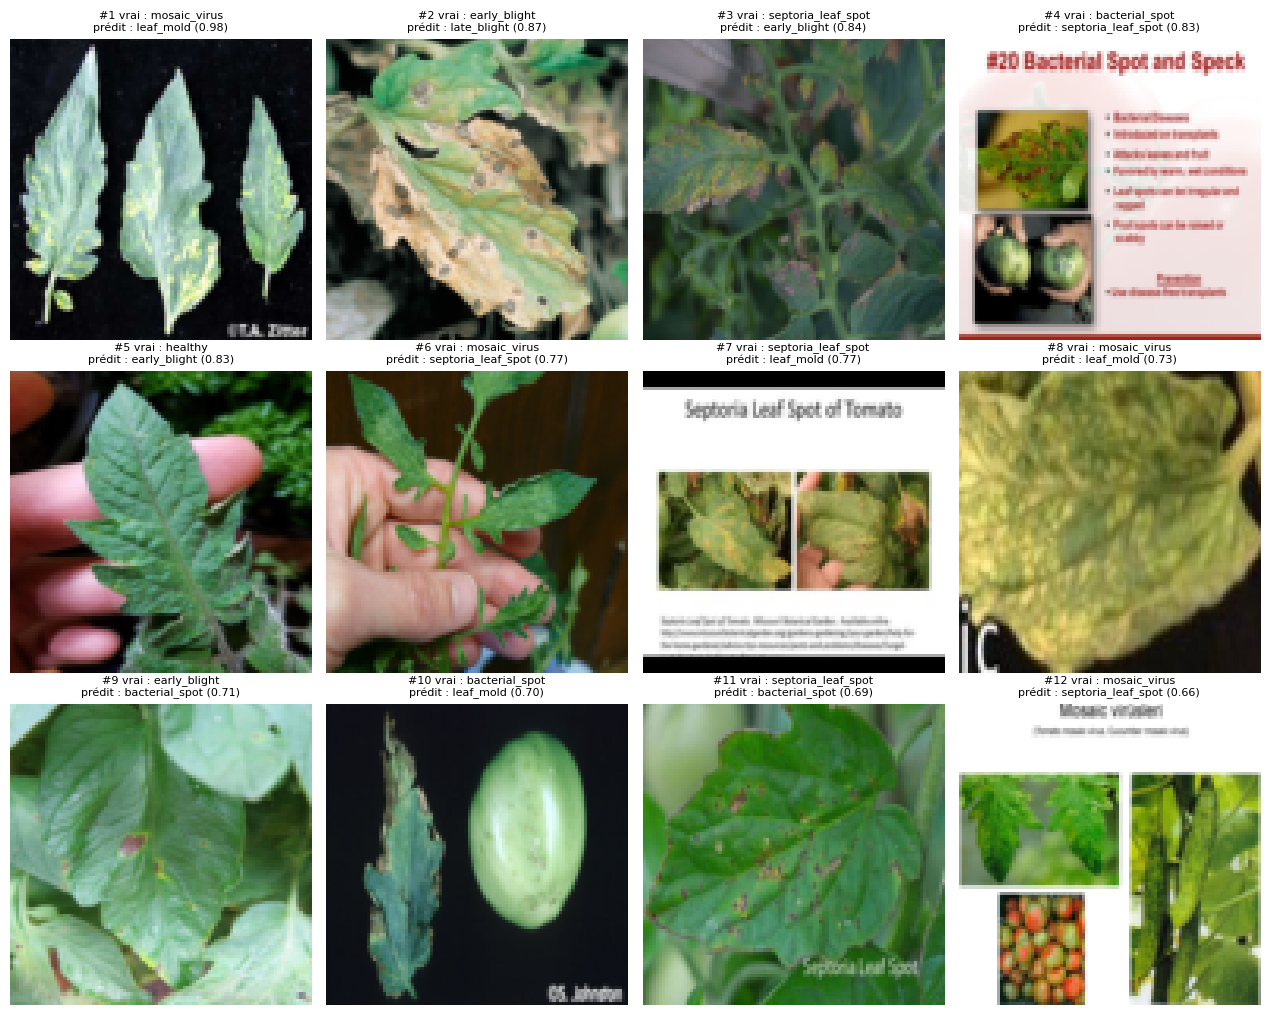

,num,fichier,vrai,predit,confiance
0,1,raw/PlantDoc-Dataset/test/Tomato leaf mosaic v...,mosaic_virus,leaf_mold,0.98
1,2,raw/PlantDoc-Dataset/test/Tomato Early blight ...,early_blight,late_blight,0.87
2,3,raw/PlantDoc-Dataset/test/Tomato Septoria leaf...,septoria_leaf_spot,early_blight,0.84
3,4,raw/PlantDoc-Dataset/test/Tomato leaf bacteria...,bacterial_spot,septoria_leaf_spot,0.83
4,5,raw/PlantDoc-Dataset/test/Tomato leaf/90e2c0.jpg,healthy,early_blight,0.83
5,6,raw/PlantDoc-Dataset/test/Tomato leaf mosaic v...,mosaic_virus,septoria_leaf_spot,0.77
6,7,raw/PlantDoc-Dataset/test/Tomato Septoria leaf...,septoria_leaf_spot,leaf_mold,0.77
7,8,raw/PlantDoc-Dataset/test/Tomato leaf mosaic v...,mosaic_virus,leaf_mold,0.73
8,9,raw/PlantDoc-Dataset/test/Tomato Early blight ...,early_blight,bacterial_spot,0.71
9,10,raw/PlantDoc-Dataset/test/Tomato leaf bacteria...,bacterial_spot,leaf_mold,0.70


In [20]:
def show_errors(name, n_show=12):
    y = D["pd_test"][1].numpy(); yp = PREDS[(name, "pd_test")]
    probs = F.softmax(predict(MODELS[name], D["pd_test"][0]), 1).numpy()
    wrong = np.where(y != yp)[0]
    print(f"{len(wrong)} erreurs sur {len(y)} images de test PlantDoc ({name})")
    wrong = wrong[np.argsort(-probs[wrong].max(1))][:n_show]       # erreurs les plus « sûres d'elles » d'abord
    cols = 4; rows = int(np.ceil(len(wrong) / cols))
    fig, ax = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows)); ax = np.atleast_2d(ax)
    for a in ax.ravel(): a.axis("off")
    for k, i in enumerate(wrong):
        a = ax.ravel()[k]; a.imshow(D["pd_test"][0][i].permute(1, 2, 0))
        a.set_title(f"#{k+1} vrai : {CLASSES[y[i]]}\nprédit : {CLASSES[yp[i]]} ({probs[i].max():.2f})", fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "erreurs_terrain.png", dpi=130); plt.show()
    return pd.DataFrame(dict(num=range(1, len(wrong) + 1), fichier=META["pd_test"].path.values[wrong],
                             vrai=[CLASSES[y[i]] for i in wrong], predit=[CLASSES[yp[i]] for i in wrong],
                             confiance=probs[wrong].max(1).round(2)))

err_table = show_errors(FINAL); display(err_table)

**À COMPLÉTER pour le rapport : une hypothèse par erreur affichée** (ouvrir l'image d'origine via la colonne `fichier`). Pistes à tester, pas des conclusions :
fond chargé ou feuille partielle ; éclairage (sur-exposition, ombre) ; symptômes visuellement proches (*early blight* / *septoria* ; *mosaic* / *yellow leaf curl*) ;
résolution trop basse après redimensionnement ; classe peu représentée dans l'entraînement ; image de site web (filigrane, schéma, plusieurs feuilles) ; étiquette douteuse.
Un tableau `# | vrai | prédit | cause probable | comment le vérifier` suffit.

### 5.3 Grad-CAM : le modèle regarde-t-il la lésion ou le fond ?
Carte d'activation pondérée par le gradient de la classe prédite, calculée sur la dernière couche convolutive. On compare le modèle PlantVillage seul au modèle final
sur **les mêmes images de terrain** : si le premier regarde le fond ou les bords et le second la feuille, c'est un résultat à documenter.

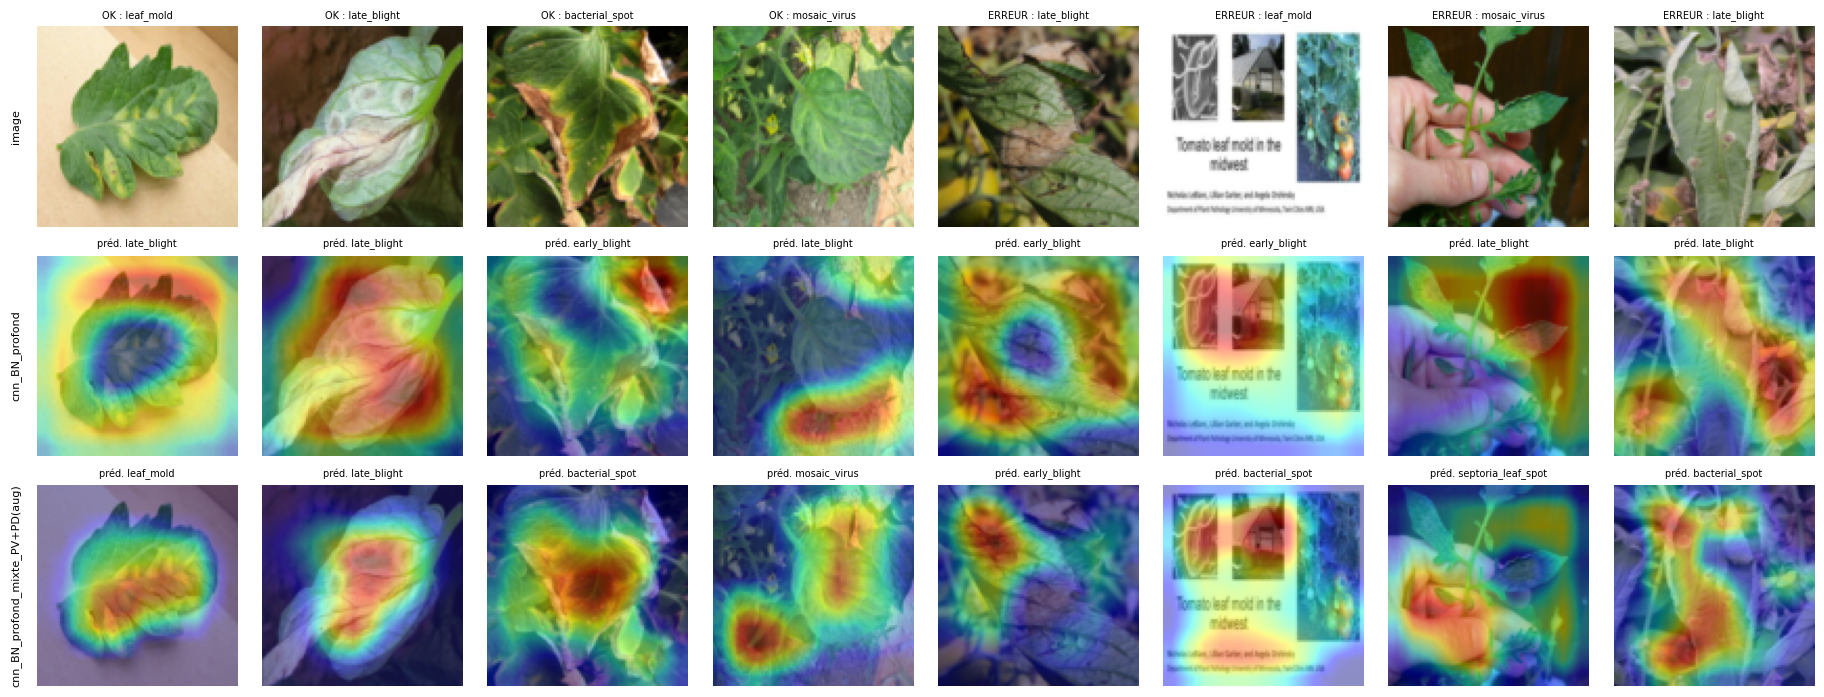

In [21]:
def gradcam(model, x, target=None):
    """x : float [0,1] B x 3 x H x W. Retourne (cartes B x H x W dans [0,1], logits)."""
    model.eval()
    with torch.no_grad():
        feats = model.features(model.norm(x))
    feats = feats.detach().requires_grad_(True)
    logits = model.fc(model.drop(model.pool(feats).flatten(1)))
    if target is None: target = logits.argmax(1)
    score = logits.gather(1, target[:, None]).sum()
    grads, = torch.autograd.grad(score, feats)
    cam = F.relu((grads.mean(dim=(2, 3), keepdim=True) * feats).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam - cam.amin(dim=(2, 3), keepdim=True); cam = cam / (cam.amax(dim=(2, 3), keepdim=True) + 1e-8)
    return cam[:, 0].detach().cpu(), logits.detach().cpu()

def compare_cam(names, key="pd_test", n_ok=4, n_err=4, fname="gradcam.png"):
    y = D[key][1].numpy(); yp_final = PREDS[(FINAL, key)]
    ok, bad = np.where(y == yp_final)[0], np.where(y != yp_final)[0]
    rng = np.random.RandomState(SEED)
    pick = list(rng.choice(ok, min(n_ok, len(ok)), replace=False)) + list(rng.choice(bad, min(n_err, len(bad)), replace=False))
    fig, ax = plt.subplots(len(names) + 1, len(pick), figsize=(2.3 * len(pick), 2.4 * (len(names) + 1)), squeeze=False)
    for j, i in enumerate(pick):
        x = (D[key][0][i:i + 1].float() / 255).to(DEVICE)
        ax[0, j].imshow(D[key][0][i].permute(1, 2, 0)); ax[0, j].axis("off")
        ax[0, j].set_title(("OK : " if y[i] == yp_final[i] else "ERREUR : ") + CLASSES[y[i]], fontsize=7)
        for r, n in enumerate(names, start=1):
            cam, lg = gradcam(MODELS[n], x)
            ax[r, j].imshow(D[key][0][i].permute(1, 2, 0)); ax[r, j].imshow(cam[0], cmap="jet", alpha=0.45); ax[r, j].axis("off")
            ax[r, j].set_title(f"préd. {CLASSES[lg.argmax(1).item()]}", fontsize=7)
    for r, n in enumerate(["image"] + list(names)):
        ax[r, 0].text(-0.08, 0.5, n, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / "figures" / fname, dpi=130); plt.show()

compare_cam([BASE_PV, FINAL])

**À COMPLÉTER pour le rapport** : décrire ce que montrent les cartes (lésion / bord de la feuille / fond / texture ?), pour les images bien classées **et** mal classées,
et si le modèle final se comporte mieux que le modèle PlantVillage seul. Attention : Grad-CAM est qualitatif, ne tirer aucune conclusion à partir d'une seule image.

## 6. Bilan : à reporter dans le rapport
* Tableau de synthèse : `outputs/tables/resultats_synthese.csv` ; figures : `outputs/figures/` ; poids des modèles : `outputs/models/`.
* **Limites et risques** (section obligatoire du rapport), à développer avec VOS chiffres :
  * test PlantDoc minuscule (quelques dizaines d'images, certaines classes avec moins de 10 exemples) : intervalles de confiance larges, une seule graine ;
  * une seule culture (tomate), 8 classes ; *target spot* et *spider mites* exclues faute d'exemples terrain ; hors-distribution non géré (feuille inconnue, autre plante, photo floue) ;
  * images PlantDoc issues du web (qualité et étiquettes non contrôlées) ; quasi-doublons non détectés (seuls les doublons exacts ont été retirés) ;
  * redimensionnement en 96 px : perte de détails fins sur les petites lésions ;
  * un faux rassurant (maladie manquée) a un coût agronomique réel : l'outil doit rester un **diagnostic préliminaire**, jamais une décision de traitement automatique.
* **Bonus facultatif** (non exigé) : transfer learning avec un modèle pré-entraîné, à ajouter après les résultats obligatoires.